In [43]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import brentq

from HATS_Code.HATS_functions import fft_cross_correlation, woodworth_itd, itd_to_angle

PathToFiles = "Audio_Files/HATS/H2/22.5"
dataL, fs = sf.read(f'{PathToFiles}/L.wav')

dataR, fs = sf.read(f'{PathToFiles}/R.wav')

L_click_idx = np.argmax(np.abs(dataL))
R_click_idx = np.argmax(np.abs(dataR))
    
click_offset = R_click_idx - L_click_idx 

L_Trimmed = dataL[L_click_idx + int(fs*2):]
R_Trimmed = dataR[R_click_idx + int(fs*2):]

min_len = min(len(L_Trimmed), len(R_Trimmed))
L_Trimmed = L_Trimmed[:min_len]
R_Trimmed = R_Trimmed[:min_len]

frame_length = 64

hop = 16

def find_onset_peak_based(data, threshold_frac=0.1):
    envelope = np.abs(data)
    peak = np.max(envelope)
    onset = np.argmax(envelope > peak * threshold_frac)
    return onset


energyL = np.array([
    np.sum(L_Trimmed[i:i+frame_length]**2)
    for i in range(0, len(L_Trimmed)-frame_length, hop)
])
noise_floorL = np.mean(energyL[:int(0.1*fs/hop)])
thresholdL = noise_floorL * 10
onset_L = find_onset_peak_based(L_Trimmed)
onset_sampleL = onset_L


energyR = np.array([
    np.sum(R_Trimmed[i:i+frame_length]**2)
    for i in range(0, len(R_Trimmed)-frame_length, hop)
])
noise_floorR = np.mean(energyR[:int(0.1*fs/hop)])
thresholdR = noise_floorR * 10
onset_R = find_onset_peak_based(R_Trimmed)
onset_sampleR = onset_R


print(f"Onset at sample {onset_sampleL} ({onset_sampleL/fs:.3f}s)")
print(f"Onset at sample {onset_sampleR} ({onset_sampleR/fs:.3f}s)")

Onset at sample 207773 (4.329s)
Onset at sample 207730 (4.328s)


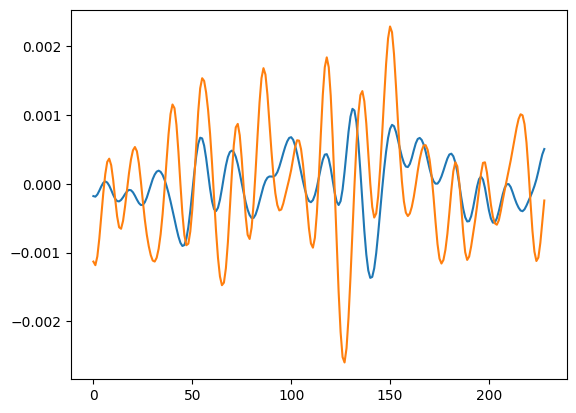

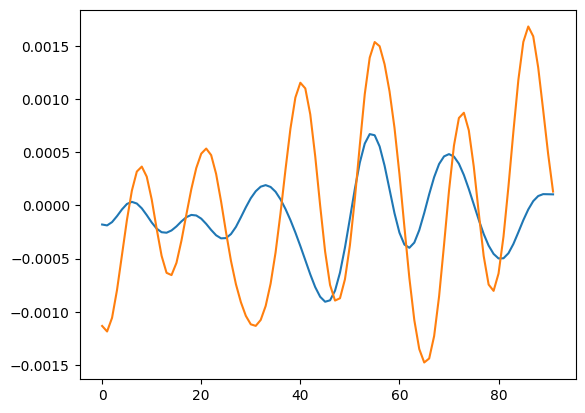

In [44]:
window_length_samples1 = 229
window_length_samples2 = 92

onset = min(onset_L, onset_R)

L_windowed1 = L_Trimmed[onset : onset + window_length_samples1]
R_windowed1 = R_Trimmed[onset : onset + window_length_samples1]

L_windowed2 = L_Trimmed[onset : onset + window_length_samples2]
R_windowed2 = R_Trimmed[onset : onset + window_length_samples2]

plt.figure()
plt.plot(L_windowed1)
plt.plot(R_windowed1)

plt.figure()
plt.plot(L_windowed2)
plt.plot(R_windowed2)

In [45]:
d = 0.21
c = 343
r = 0.0875 
angle = -45

correlation = fft_cross_correlation(L_windowed1, R_windowed1)

n = len(L_windowed1)
lags = np.arange(-n//2, n//2)
lags = lags[:len(correlation)]

max_itd_samples = int((d / c) * (np.pi/2 + 1) * fs)
mask = (lags >= -max_itd_samples) & (lags <= max_itd_samples)
itd_samples = lags[mask][np.argmax(correlation[mask])]
itd_seconds = itd_samples / fs
        
angle_deg = itd_to_angle(itd_seconds, r, fs)
print(angle_deg)

itd_expected = woodworth_itd(float(angle), r)
print("Diff ", itd_expected-itd_seconds)

31.17211407601786
Diff  -0.000651574390625169


In [46]:
d = 0.21
c = 343
r = 0.0875 
angle = -45

correlation = fft_cross_correlation(L_windowed2, R_windowed2)

n = len(L_windowed2)
lags = np.arange(-n//2, n//2)
lags = lags[:len(correlation)]

max_itd_samples = int((d / c) * (np.pi/2 + 1) * fs)
mask = (lags >= -max_itd_samples) & (lags <= max_itd_samples)
itd_samples = lags[mask][np.argmax(correlation[mask])]
itd_seconds = itd_samples / fs
        
angle_deg = itd_to_angle(itd_seconds, r, fs)
print(angle_deg)


itd_expected = woodworth_itd(float(angle), r)
print("Diff ", itd_expected-itd_seconds)

33.70978794239421
Diff  -0.0006724077239585023


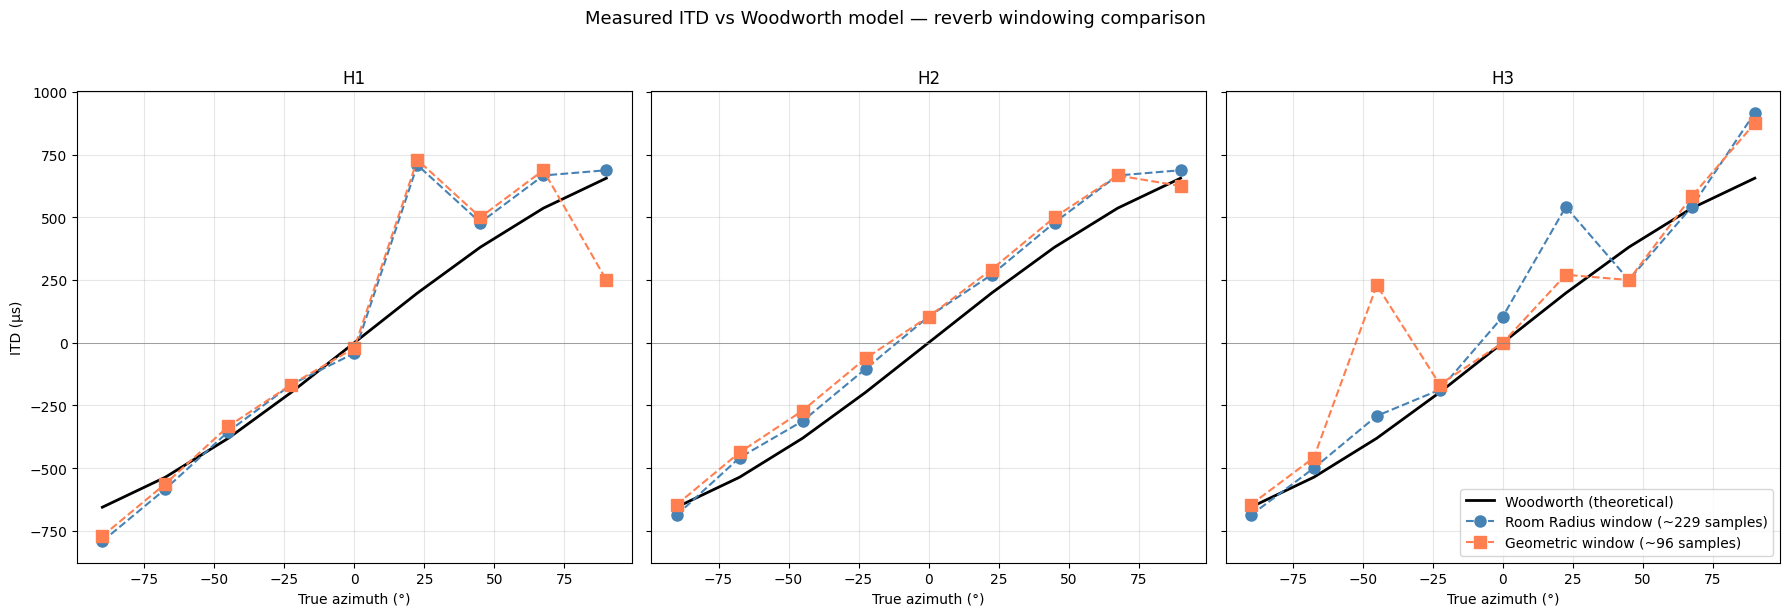

In [51]:
from pathlib import Path
angles = ["-90", "-67.5", "-45", "-22.5", "0", "22.5", "45", "67.5", "90"]
heights = ["H1", "H2", "H3"]  
PathToFiles = "Audio_Files/HATS/"

recordings = {}

for height in heights:
    recordings[height] = {}
    for angle in angles:
        folder = Path(PathToFiles) / str(height) / str(angle)
        
        if folder.is_dir():
            recordings[height][angle] = {
                'L': folder / "L.wav",
                'R': folder / "R.wav"
            }
        else:
            print(f"Missing folder: {folder}")
            
d = 0.21
c = 343
r = 0.0875 

results = {}

for height, angle_dict in recordings.items():
    results[height] = {}
    for angle, files in angle_dict.items():
        dataL, fs = sf.read(files['L'])
        dataR, fs = sf.read(files['R'])
        
        L_click_idx = np.argmax(np.abs(dataL))
        R_click_idx = np.argmax(np.abs(dataR))
            
        click_offset = R_click_idx - L_click_idx 

        L_Trimmed = dataL[L_click_idx + int(fs*2):]
        R_Trimmed = dataR[R_click_idx + int(fs*2):]

        min_len = min(len(L_Trimmed), len(R_Trimmed))
        L_Trimmed = L_Trimmed[:min_len]
        R_Trimmed = R_Trimmed[:min_len]
        
        energyL = np.array([
            np.sum(L_Trimmed[i:i+frame_length]**2)
            for i in range(0, len(L_Trimmed)-frame_length, hop)
        ])
        noise_floorL = np.mean(energyL[:int(0.1*fs/hop)])
        thresholdL = noise_floorL * 10
        onset_L = find_onset_peak_based(L_Trimmed)
        onset_sampleL = onset_L


        energyR = np.array([
            np.sum(R_Trimmed[i:i+frame_length]**2)
            for i in range(0, len(R_Trimmed)-frame_length, hop)
        ])
        noise_floorR = np.mean(energyR[:int(0.1*fs/hop)])
        thresholdR = noise_floorR * 10
        onset_R = find_onset_peak_based(R_Trimmed)
        onset_sampleR = onset_R
        
        onset = min(onset_L, onset_R)
    
        L_windowed1 = L_Trimmed[onset : onset + window_length_samples1]
        R_windowed1 = R_Trimmed[onset : onset + window_length_samples1]

        L_windowed2 = L_Trimmed[onset : onset + window_length_samples2]
        R_windowed2 = R_Trimmed[onset : onset + window_length_samples2]


        correlation = fft_cross_correlation(L_windowed1, R_windowed1)

        n = len(L_windowed1)
        lags = np.arange(-n//2, n//2)
        lags = lags[:len(correlation)]

        max_itd_samples = int((d / c) * (np.pi/2 + 1) * fs)
        mask = (lags >= -max_itd_samples) & (lags <= max_itd_samples)
        itd_samples = lags[mask][np.argmax(correlation[mask])]
        itd_seconds1 = itd_samples / fs
                
        angle_deg1 = itd_to_angle(itd_seconds1, r, fs)



        correlation = fft_cross_correlation(L_windowed2, R_windowed2)

        n = len(L_windowed2)
        lags = np.arange(-n//2, n//2)
        lags = lags[:len(correlation)]

        max_itd_samples = int((d / c) * (np.pi/2 + 1) * fs)
        mask = (lags >= -max_itd_samples) & (lags <= max_itd_samples)
        itd_samples = lags[mask][np.argmax(correlation[mask])]
        itd_seconds2 = itd_samples / fs
            
        angle_deg2 = itd_to_angle(itd_seconds2, r, fs)
        
        results[height][angle] = {
            'expected': angle,
            'calculated1': angle_deg1,
            'calculated2': angle_deg2,
            'itd1': itd_seconds1,
            'itd2': itd_seconds2,
        }   

angles = [-90, -67.5, -45, -22.5, 0, 22.5, 45, 67.5, 90]
theoretical = [woodworth_itd(a, r, c) * 1e6 for a in angles]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

for ax, height in zip(axes, ['H1', 'H2', 'H3']):
    itd_stat = [results[height][str(a)]['itd1'] for a in angles]
    itd_geom = [results[height][str(a)]['itd2'] for a in angles]

    itd_stat_us = np.array(itd_stat) * 1e6
    itd_geom_us = np.array(itd_geom) * 1e6

    ax.plot(angles, theoretical, 'k-', linewidth=2, label='Woodworth (theoretical)')
    ax.plot(angles, itd_stat_us, 'o--', color='steelblue', markersize=8,
            label='Room Radius window (~229 samples)')
    ax.plot(angles, itd_geom_us, 's--', color='coral', markersize=8,
            label='Geometric window (~96 samples)')

    ax.set_xlabel('True azimuth (°)')
    ax.set_title(height)
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('ITD (µs)')
axes[-1].legend(loc='lower right')

fig.suptitle('Measured ITD vs Woodworth model — reverb windowing comparison',
             fontsize=13, y=1.02)
plt.tight_layout()
# save_fig(fig, "itd_vs_woodworth_window_comparison_all")
plt.show()
plt.close(fig)